# SMH vs XLU Dual-Momentum Backtest

**Thanh Ly** · MSBA Program, California State University, Sacramento · ORCID [0009-0002-5249-7955](https://orcid.org/0009-0002-5249-7955)

Companion code for the manuscript *Dual Momentum in Equity-Utility Portfolios: Empirical Performance, Risk-Adjusted Returns, and Volatility Dynamics*.
Running this notebook top to bottom reproduces every table and figure in the paper.

## Hypothesis

Expect lower CAGR, but a much smoother ride.

Given SMH's relentless, AI-fueled secular momentum, trend-following rules will inevitably lag a simple buy-and-hold approach during strong bull runs. However, dual momentum should deliver materially better risk-adjusted returns (Sharpe/Sortino) by sidestepping deep market crashes (like 2008 and 2022) via BIL/GLD safety pivots.

We are willingly giving up peak upside to cap max drawdowns and shorten recovery times.

In [1]:
"""
SMH vs XLU Dual-Momentum Backtest
Universe:
  - SMH (Semiconductors)  = Asset A
  - XLU (Utilities)       = Asset B
  - GLD (Gold)            = Safe haven (Asset C)
  - BIL (T-Bills)         = Cash proxy / risk-free hurdle
  - Benchmark             = SMH buy-and-hold
Strategy (Gary Antonacci's Dual Momentum), evaluated at each month-end:
  Layer 1 (Relative): pick the higher 12-month return of SMH vs XLU.
  Layer 2 (Absolute): if that winner beat BIL over 12 months -> hold it;
                      otherwise -> hold GLD.
The signal is applied to the NEXT month's return (shift(1)) to avoid
look-ahead bias, and a 10 bps cost is charged whenever the position changes.
"""
# 1. Imports & settings
# Install dependencies first if needed:  pip install -r requirements.txt
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

TICKERS      = ["SMH", "XLU", "GLD", "BIL"]
ASSET_A      = "SMH"   # semiconductors
ASSET_B      = "XLU"   # utilities
SAFE_ASSET   = "GLD"   # safe haven
CASH_PROXY   = "BIL"   # risk-free hurdle
BENCHMARK    = "SMH"
START_DATE   = "2000-01-01"
END_DATE     = "2026-07-31"  # last month-end used in the paper
LOOKBACK     = 12          # months of momentum
COST         = 0.001       # 10 bps transaction cost per switch
INITIAL      = 10_000      # starting wealth
PER_YEAR     = 12

# Reproducibility: the first run downloads prices and saves them to data/.
# Later runs reuse that file, so results don't drift when Yahoo revises adjusted prices.
DATA_FILE    = Path("data/monthly_prices.csv")
FIG_DIR      = Path("figures");  FIG_DIR.mkdir(exist_ok=True)
RES_DIR      = Path("results");  RES_DIR.mkdir(exist_ok=True)
DPI          = 300         # journal-quality figures

In [2]:
# 2. Download & prep data (common date range, month-end prices)
def get_monthly_prices(tickers, start):
    """Download adjusted daily closes, keep the common range, resample to month-end."""
    data = yf.download(tickers, start=start, auto_adjust=True, progress=False)
    prices = data["Close"] if isinstance(data.columns, pd.MultiIndex) else data[["Close"]]
    prices = prices.loc[:, tickers].dropna(how="any")          # common date range
    return prices.resample("ME").last().dropna()               # month-end prices

if DATA_FILE.exists():
    monthly = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
    print(f"Loaded cached prices from {DATA_FILE}")
else:
    monthly = get_monthly_prices(TICKERS, START_DATE).loc[:END_DATE]
    DATA_FILE.parent.mkdir(exist_ok=True)
    monthly.to_csv(DATA_FILE)
    print(f"Downloaded prices and saved to {DATA_FILE}")

monthly = monthly.loc[:END_DATE, TICKERS]
monthly_ret = monthly.pct_change()                             # monthly returns
print("Data range:", monthly.index.min().date(), "->", monthly.index.max().date(),
      "| months:", len(monthly))

Downloaded prices and saved to data/monthly_prices.csv
Data range: 2007-05-31 -> 2026-07-31 | months: 231


In [3]:
# 3. The dual-momentum engine
def dual_momentum(prices, a, b, safe, cash, lookback=LOOKBACK, cost=COST):
    """Dual momentum: hold the winner of A vs B, but only if it beat cash, else safe."""
    ret  = prices.pct_change()
    mom  = prices / prices.shift(lookback) - 1                 # 12-month momentum
    # Layer 1: relative momentum -> winner of A vs B (NaN while momentum unknown)
    winner = pd.Series(np.where(mom[a] >= mom[b], a, b), index=prices.index, dtype=object)
    winner[mom[[a, b]].isna().any(axis=1)] = np.nan
    # Layer 2: absolute momentum -> keep winner only if it beat cash, else safe
    winner_mom = np.where(winner == a, mom[a], mom[b])
    final = pd.Series(np.where(winner_mom > mom[cash], winner, safe), index=prices.index, dtype=object)
    final[winner.isna()] = np.nan
    # Apply signal to NEXT month's return (prevents look-ahead bias)
    held = final.shift(1)
    gross = pd.Series(
        [np.nan if pd.isna(p) else ret.loc[d, p] for d, p in held.items()],
        index=prices.index,
    )
    # Transaction cost only when the position changes (never on the first hold)
    switch = held.ne(held.shift(1)).fillna(False).astype(int)
    first = held.first_valid_index()
    if first is not None:
        switch.loc[first] = 0
    switch[held.isna()] = 0
    net = gross - switch * cost
    return pd.DataFrame({"Winner": winner, "Signal": final, "Held": held,
                         "Switch": switch, "Net_Return": net})

strat = dual_momentum(monthly, ASSET_A, ASSET_B, SAFE_ASSET, CASH_PROXY)

In [4]:
# 4. Performance metrics
def cagr(r):
    return (1 + r.dropna()).prod() ** (PER_YEAR / len(r.dropna())) - 1

def sharpe(r, rf):
    x = (r - rf).dropna()
    return x.mean() / x.std(ddof=1) * np.sqrt(PER_YEAR)

def sortino(r, rf):
    x = (r - rf).dropna()
    return x.mean() / np.sqrt((x[x < 0] ** 2).mean()) * np.sqrt(PER_YEAR)

def max_dd(r):
    wealth = (1 + r.dropna()).cumprod()
    return (wealth / wealth.cummax() - 1).min()

def dd_duration(r):
    """Longest run of consecutive months spent below the previous peak."""
    wealth = (1 + r.dropna()).cumprod()
    underwater = (wealth / wealth.cummax() - 1) < 0
    best = cur = 0
    for flag in underwater:
        cur = cur + 1 if flag else 0
        best = max(best, cur)
    return best

In [5]:
# 5. Build comparison strategies & performance table (Table 3 in the paper)
benchmark   = monthly_ret[BENCHMARK]                          # SMH buy-and-hold
equal_wt    = monthly_ret[[ASSET_A, ASSET_B]].mean(axis=1)     # 50/50 SMH-XLU

# Relative-momentum-only: always hold the winner (no safe-haven filter)
rel_held = strat["Winner"].shift(1)
rel_mom = pd.Series(
    [np.nan if pd.isna(p) else monthly_ret.loc[d, p] for d, p in rel_held.items()],
    index=monthly.index,
)
rel_sw = rel_held.ne(rel_held.shift(1)).fillna(False).astype(int)
rel_sw[rel_held.first_valid_index()] = 0
rel_sw[rel_held.isna()] = 0
rel_mom -= rel_sw * COST

returns = pd.DataFrame({
    "Dual Momentum":     strat["Net_Return"],
    "SMH Buy-and-Hold":  benchmark,
    "50/50 SMH-XLU":     equal_wt,
    "Relative Momentum": rel_mom,
    "BIL":               monthly_ret[CASH_PROXY],
})
START_EVAL = strat["Net_Return"].first_valid_index()
returns = returns.loc[START_EVAL:]
print("Evaluation start:", START_EVAL)
print("Evaluation end:", returns.index.max())
print("Number of months:", len(returns))

rf = returns["BIL"]
summary = pd.DataFrame({
    col: {
        "CAGR":              cagr(returns[col]),
        "Sharpe":            sharpe(returns[col], rf),
        "Sortino":           sortino(returns[col], rf),
        "Max Drawdown":      max_dd(returns[col]),
        "DD Duration (mo)":  dd_duration(returns[col]),
        "Terminal Wealth":   INITIAL * (1 + returns[col].dropna()).prod(),
    }
    for col in ["Dual Momentum", "SMH Buy-and-Hold", "50/50 SMH-XLU", "Relative Momentum"]
}).T
print("\n PERFORMANCE SUMMARY ")
print(summary.round(4))

allocation = strat.loc[START_EVAL:, "Held"].value_counts(normalize=True)
print("\n ALLOCATION (share of months held) ")
print(allocation.round(4))
print("Total switches:", int(strat["Switch"].sum()))

summary.round(4).to_csv(RES_DIR / "performance_summary.csv")
allocation.round(4).to_csv(RES_DIR / "allocation.csv")

Evaluation start: 2008-06-30 00:00:00
Evaluation end: 2026-07-31 00:00:00
Number of months: 218

 PERFORMANCE SUMMARY 
                    CAGR  Sharpe  Sortino  Max Drawdown  DD Duration (mo)  \
Dual Momentum     0.2119  0.9287   1.0139       -0.2249           31.0000   
SMH Buy-and-Hold  0.2234  0.8529   0.8861       -0.4445           28.0000   
50/50 SMH-XLU     0.1594  0.8910   0.8462       -0.3987           30.0000   
Relative Momentum 0.1732  0.7735   0.8326       -0.3637           31.0000   

                   Terminal Wealth  
Dual Momentum         328,560.8984  
SMH Buy-and-Hold      389,917.8546  
50/50 SMH-XLU         146,948.2766  
Relative Momentum     182,034.9729  

 ALLOCATION (share of months held) 
Held
SMH   0.6514
XLU   0.2615
GLD   0.0872
Name: proportion, dtype: float64
Total switches: 26


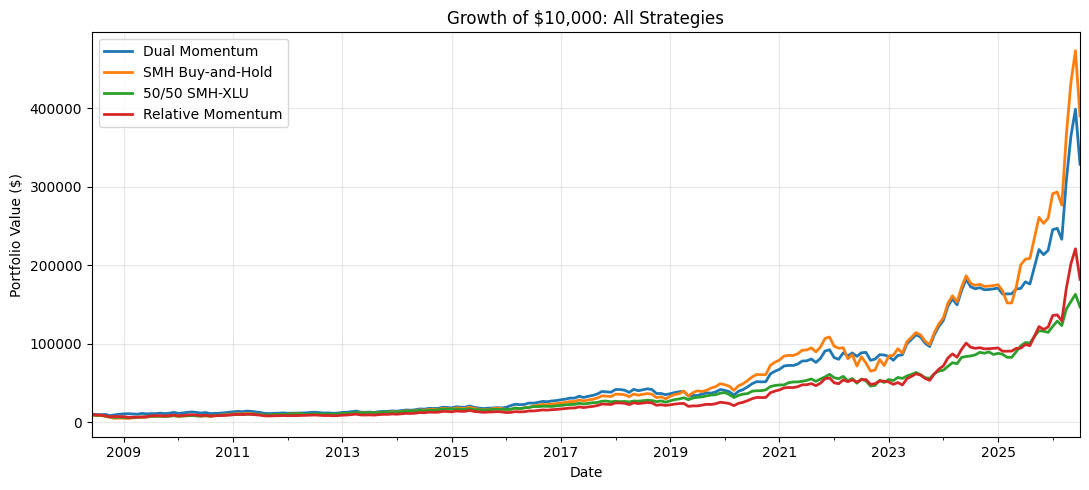

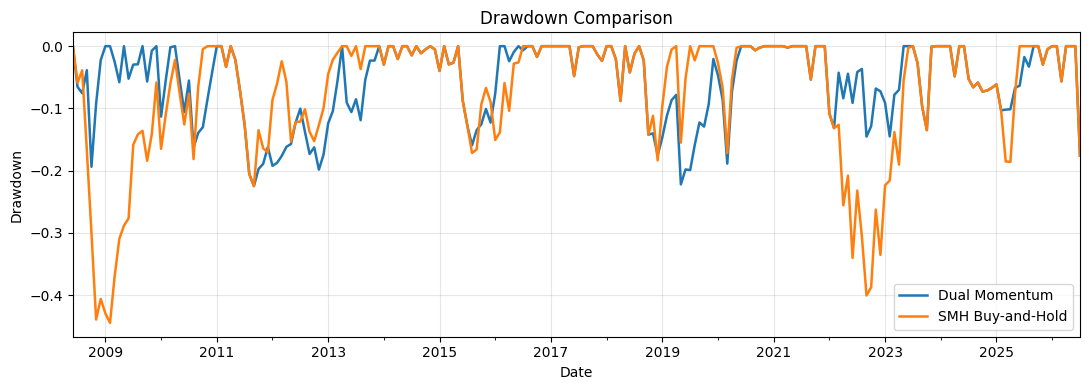

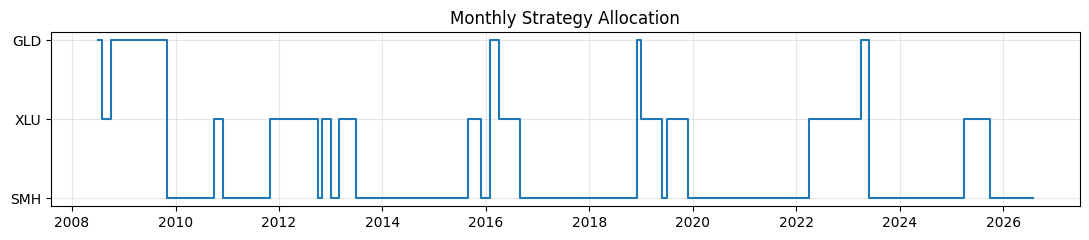

In [6]:
# 6. Charts (saved as Figures 1-3 for the paper)
def wealth_curve(r):
    return INITIAL * (1 + r.dropna()).cumprod()

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=DPI, bbox_inches="tight")

# 6a. Equity curve: all four strategies  -> Figure 1
ax = pd.DataFrame({
    "Dual Momentum":     wealth_curve(returns["Dual Momentum"]),
    "SMH Buy-and-Hold":  wealth_curve(returns["SMH Buy-and-Hold"]),
    "50/50 SMH-XLU":     wealth_curve(returns["50/50 SMH-XLU"]),
    "Relative Momentum": wealth_curve(returns["Relative Momentum"]),
}).plot(figsize=(11, 5), linewidth=2)
ax.set_title("Growth of $10,000: All Strategies")
ax.set_ylabel("Portfolio Value ($)")
ax.grid(alpha=0.3)
plt.tight_layout(); save(ax.figure, "figure1_equity_curve.png"); plt.show()

# 6b. Drawdown comparison  -> Figure 2
dd = pd.DataFrame({
    "Dual Momentum":    wealth_curve(returns["Dual Momentum"]) / wealth_curve(returns["Dual Momentum"]).cummax() - 1,
    "SMH Buy-and-Hold": wealth_curve(returns["SMH Buy-and-Hold"]) / wealth_curve(returns["SMH Buy-and-Hold"]).cummax() - 1,
})
ax = dd.plot(figsize=(11, 4), linewidth=1.8)
ax.set_title("Drawdown Comparison")
ax.set_ylabel("Drawdown")
ax.grid(alpha=0.3)
plt.tight_layout(); save(ax.figure, "figure2_drawdown.png"); plt.show()

# 6c. Allocation timeline  -> Figure 3
codes = {ASSET_A: 1, ASSET_B: 2, SAFE_ASSET: 3}
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.step(strat["Held"].index, strat["Held"].map(codes), where="post", linewidth=1.5)
ax.set_yticks(list(codes.values())); ax.set_yticklabels(list(codes.keys()))
ax.set_title("Monthly Strategy Allocation")
ax.grid(alpha=0.3)
plt.tight_layout(); save(fig, "figure3_allocation.png"); plt.show()

In [7]:
# 7. Sensitivity tests (Tables 5 and 6 in the paper)
print("\n TRANSACTION-COST SENSITIVITY ")
cost_rows = []
for cost in [0.0, 0.0005, 0.001, 0.0025]:
    net = strat["Net_Return"] + strat["Switch"] * COST - strat["Switch"] * cost
    cost_rows.append({"Cost (bps)": round(cost * 10000), "CAGR": cagr(net),
                      "Sharpe": sharpe(net, rf), "Max Drawdown": max_dd(net)})
    print(f"{cost*10000:.0f} bps -> CAGR {cagr(net):.4f} | "
          f"Sharpe {sharpe(net, rf):.4f} | MaxDD {max_dd(net):.4f}")

print("\n LOOKBACK SENSITIVITY ")
lb_rows = []
for lb in [6, 9, 12]:
    s = dual_momentum(monthly, ASSET_A, ASSET_B, SAFE_ASSET, CASH_PROXY, lookback=lb)
    lb_rows.append({"Look-back (months)": lb, "CAGR": cagr(s["Net_Return"]),
                    "Sharpe": sharpe(s["Net_Return"], rf), "Max Drawdown": max_dd(s["Net_Return"]),
                    "Switches": int(s["Switch"].sum())})
    print(f"{lb} months -> CAGR {cagr(s['Net_Return']):.4f} | "
          f"Sharpe {sharpe(s['Net_Return'], rf):.4f} | "
          f"MaxDD {max_dd(s['Net_Return']):.4f} | Switches {int(s['Switch'].sum())}")

pd.DataFrame(cost_rows).round(4).to_csv(RES_DIR / "cost_sensitivity.csv", index=False)
pd.DataFrame(lb_rows).round(4).to_csv(RES_DIR / "lookback_sensitivity.csv", index=False)


 TRANSACTION-COST SENSITIVITY 
0 bps -> CAGR 0.2137 | Sharpe 0.9351 | MaxDD -0.2249
5 bps -> CAGR 0.2128 | Sharpe 0.9319 | MaxDD -0.2249
10 bps -> CAGR 0.2119 | Sharpe 0.9287 | MaxDD -0.2249
25 bps -> CAGR 0.2094 | Sharpe 0.9191 | MaxDD -0.2258

 LOOKBACK SENSITIVITY 
6 months -> CAGR 0.1546 | Sharpe 0.7774 | MaxDD -0.4384 | Switches 47
9 months -> CAGR 0.1912 | Sharpe 0.8876 | MaxDD -0.2714 | Switches 27
12 months -> CAGR 0.2119 | Sharpe 0.9287 | MaxDD -0.2249 | Switches 26


# Key Takeaways & Strategy Verdict

*Numbers below are from the run on data through July 2026 (evaluation June 2008 to July 2026, 218 months).*

The backtest validated our hypothesis: Dual Momentum successfully sacrificed a small portion of raw return to deliver a dramatically smoother, safer equity curve.

**The Return Tradeoff:** Dual Momentum returned 21.2% CAGR vs. 22.3% for SMH buy-and-hold (\$329k vs. \$390k terminal wealth). Lagging by ~115 bps/year is the expected tax of trend-following during a secular bull run.

**The Protection Payoff:** Peak drawdown was cut roughly in half (-22.5% vs. -44.5%), driving superior risk-adjusted scores across both Sharpe (0.93 vs. 0.85) and Sortino (1.01 vs. 0.89). The longest drawdown lasted slightly longer, though (31 vs. 28 months).

**How It Won:** Protection didn't come from sitting in Gold (held only ~9% of the time, mostly during 2008-09); it came from shifting into Utilities (26% of the time) during market chop. The strategy's edge easily survived 25 bps transaction friction (Sharpe still 0.92).

**Bottom Line:** Pure SMH buy-and-hold is for aggressive investors who can survive losing almost half their portfolio value. Dual Momentum is the superior strategy for risk-conscious capital that values drawdown protection over raw terminal wealth.


GARCH ANALYSIS — Dual Momentum
Obs: 218 | Mean: 1.8133% | Vol: 6.3826%


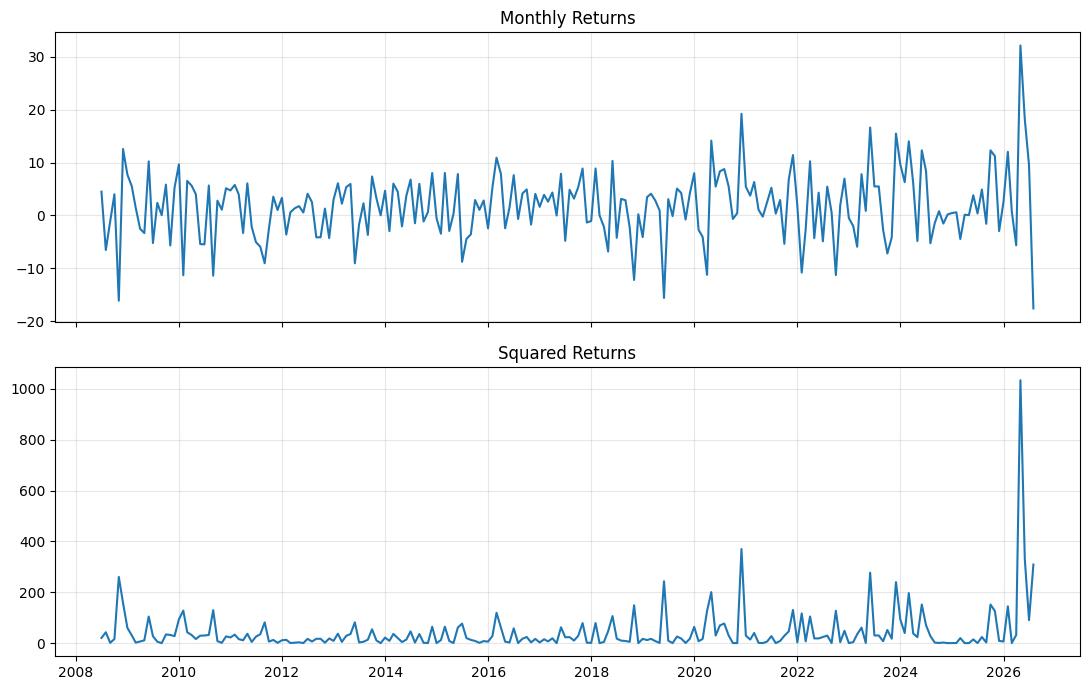

In [10]:
# 8. GARCH Volatility Analysis
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats

# Helper functions
def lb_test(series, lags):
    return acorr_ljungbox(series, lags=[lags], return_df=True).iloc[0]

def arch_test(series, lags):
    stat, pval, _, _ = het_arch(series, nlags=lags)
    return stat, pval

def show_test(name, stat, pval):
    print(f"{name}: stat={stat:.4f}, p={pval:.4f}")

# 8a. Prepare returns (in percent)
garch_returns = returns["Dual Momentum"].dropna() * 100
print("\nGARCH ANALYSIS — Dual Momentum")
print(f"Obs: {len(garch_returns)} | Mean: {garch_returns.mean():.4f}% | Vol: {garch_returns.std():.4f}%")

# Plot returns + squared returns
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(garch_returns); ax[0].set_title("Monthly Returns"); ax[0].grid(alpha=0.3)
ax[1].plot(garch_returns**2); ax[1].set_title("Squared Returns"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

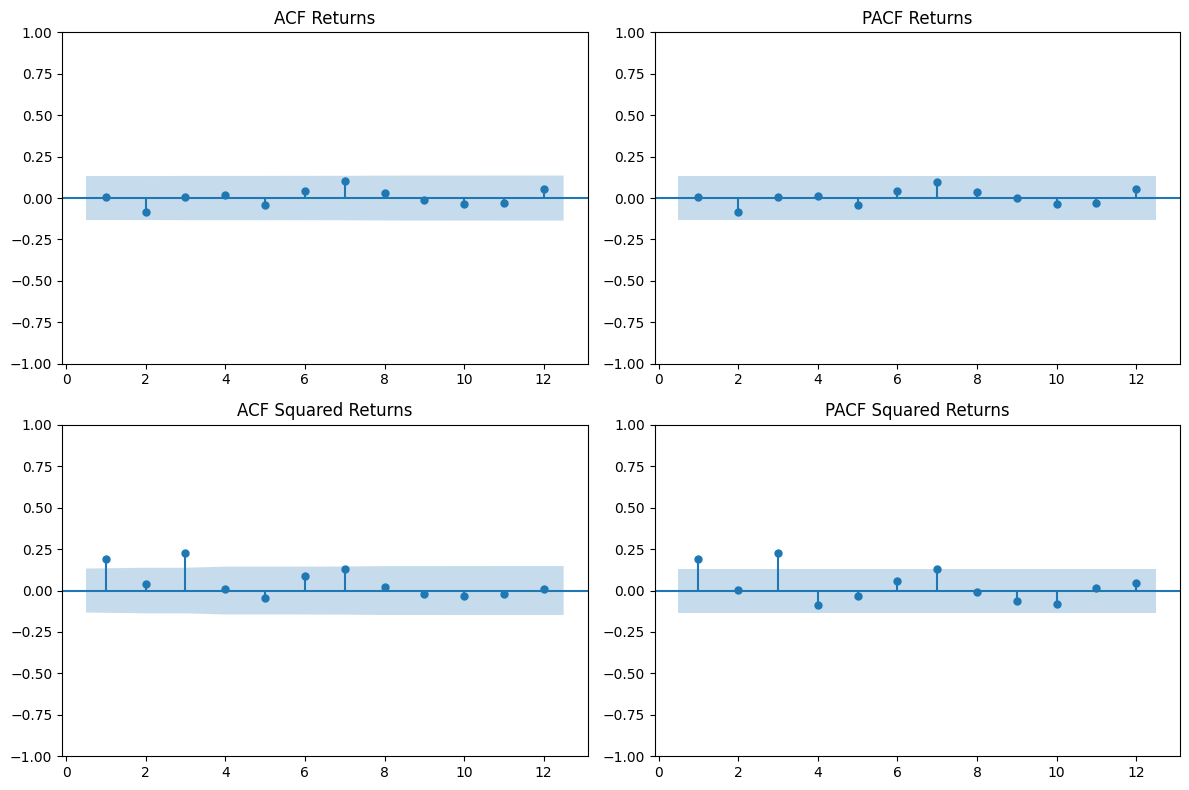


Pre-Fitting Diagnostics
LB (Squared Residuals): stat=22.6983, p=0.0304
ARCH LM: stat=32.8162, p=0.0010
LB (Residuals): stat=6.1873, p=0.9063

GARCH(1,1) Summary
                     Constant Mean - GARCH Model Results                      
Dep. Variable:          Dual Momentum   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -707.390
Distribution:                  Normal   AIC:                           1422.78
Method:            Maximum Likelihood   BIC:                           1436.32
                                        No. Observations:                  218
Date:                Thu, Nov 05 2026   Df Residuals:                      217
Time:                        18:11:31   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|

In [11]:
# 8b. ACF/PACF
lags = 12
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
plot_acf(garch_returns, lags=lags, zero=False, ax=ax[0,0]);  ax[0,0].set_title("ACF Returns")
plot_pacf(garch_returns, lags=lags, zero=False, ax=ax[0,1]); ax[0,1].set_title("PACF Returns")
plot_acf(garch_returns**2, lags=lags, zero=False, ax=ax[1,0]);  ax[1,0].set_title("ACF Squared Returns")
plot_pacf(garch_returns**2, lags=lags, zero=False, ax=ax[1,1]); ax[1,1].set_title("PACF Squared Returns")
plt.tight_layout(); plt.show()

# 8c. Pre-fitting diagnostics (12 lags)
resid = garch_returns - garch_returns.mean()
lb_sq = lb_test(resid**2, lags)
arch_stat, arch_p = arch_test(resid, lags)
lb_mean = lb_test(resid, lags)
print("\nPre-Fitting Diagnostics")
show_test("LB (Squared Residuals)", lb_sq["lb_stat"], lb_sq["lb_pvalue"])
show_test("ARCH LM", arch_stat, arch_p)
show_test("LB (Residuals)", lb_mean["lb_stat"], lb_mean["lb_pvalue"])

# 8d. Fit GARCH(1,1)  (Table 7 in the paper)
model = arch_model(garch_returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
res = model.fit(update_freq=5, disp="off")
print("\nGARCH(1,1) Summary")
print(res.summary())
garch_params = pd.DataFrame({"Estimate": res.params, "StdErr": res.std_err, "pval": res.pvalues}).round(4)
print("\nParameters")
print(garch_params)
garch_params.to_csv(RES_DIR / "garch_parameters.csv")


Volatility Persistence
alpha=0.0570, beta=0.9380, alpha+beta=0.9950
Mean reverting

Post-Model Diagnostics
LB (Std Residuals): stat=5.5834, p=0.9356
LB (Squared Std Residuals): stat=9.8632, p=0.6280
ARCH LM (Std Residuals): stat=16.2543, p=0.1799


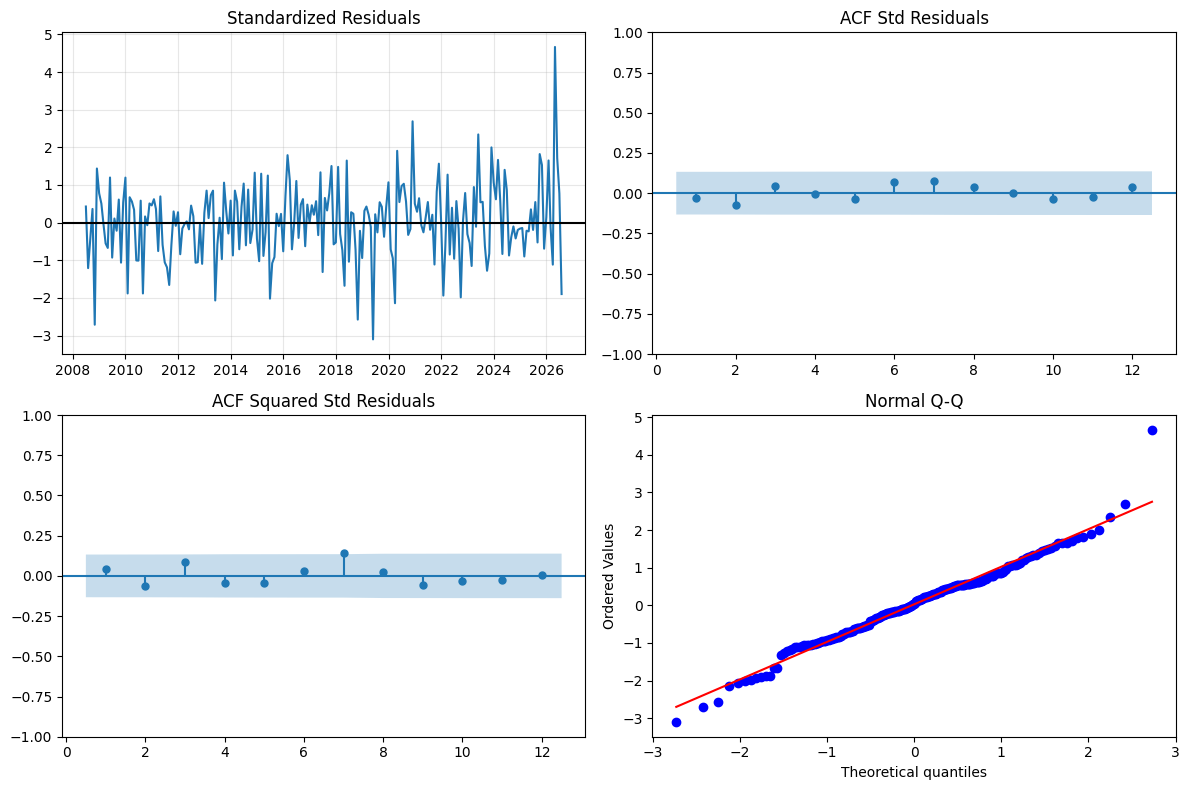

In [12]:
# 8e. Volatility persistence
alpha = res.params.get("alpha[1]", np.nan)
beta = res.params.get("beta[1]", np.nan)
persistence = alpha + beta
print("\nVolatility Persistence")
print(f"alpha={alpha:.4f}, beta={beta:.4f}, alpha+beta={persistence:.4f}")
print("Mean reverting" if persistence < 1 else "Highly persistent / non-stationary")

# 8f. Post-model diagnostics
std = res.std_resid.dropna()
lb_std = lb_test(std, lags)
lb_std_sq = lb_test(std**2, lags)
arch_post_stat, arch_post_p = arch_test(std, lags)
print("\nPost-Model Diagnostics")
show_test("LB (Std Residuals)", lb_std["lb_stat"], lb_std["lb_pvalue"])
show_test("LB (Squared Std Residuals)", lb_std_sq["lb_stat"], lb_std_sq["lb_pvalue"])
show_test("ARCH LM (Std Residuals)", arch_post_stat, arch_post_p)

# 8g. Diagnostic plots
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0,0].plot(std); ax[0,0].axhline(0, color="black"); ax[0,0].set_title("Standardized Residuals"); ax[0,0].grid(alpha=0.3)
plot_acf(std, lags=lags, zero=False, ax=ax[0,1]); ax[0,1].set_title("ACF Std Residuals")
plot_acf(std**2, lags=lags, zero=False, ax=ax[1,0]); ax[1,0].set_title("ACF Squared Std Residuals")
stats.probplot(std, dist="norm", plot=ax[1,1]); ax[1,1].set_title("Normal Q-Q")
plt.tight_layout(); plt.show()

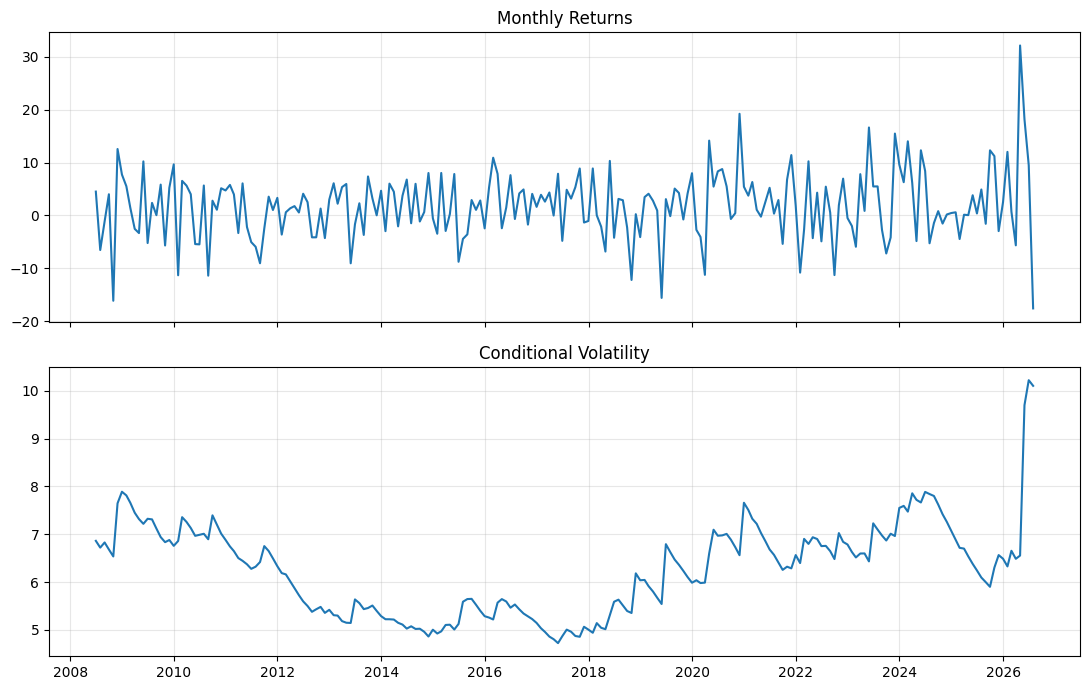


Volatility Forecast (monthly, %)
   Month Ahead  Variance  Volatility (%)
0            1  117.2222         10.8269
1            2  117.1365         10.8230
2            3  117.0513         10.8190
3            4  116.9664         10.8151
4            5  116.8820         10.8112
5            6  116.7980         10.8073


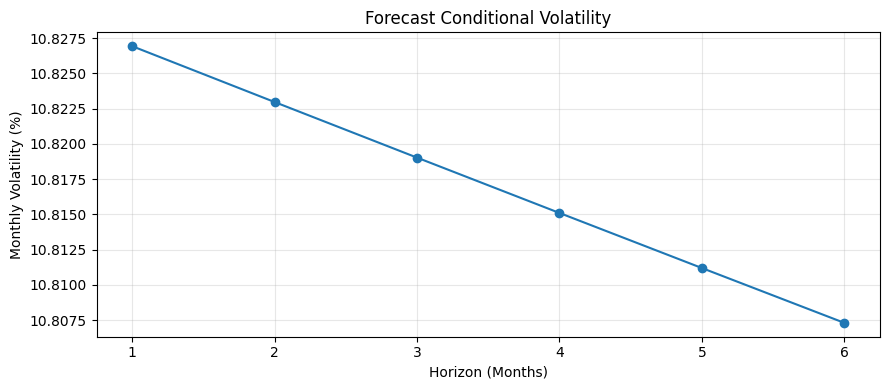

In [13]:
# 8h. Fitted conditional volatility
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(garch_returns); ax[0].set_title("Monthly Returns"); ax[0].grid(alpha=0.3)
ax[1].plot(res.conditional_volatility); ax[1].set_title("Conditional Volatility"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 8i. Forecast volatility (Table 8 in the paper)
# Note: returns are monthly and in percent, so these are MONTHLY volatilities (not annualized).
h = 6
fc = res.forecast(horizon=h)
var_fc = fc.variance.iloc[-1]
vol_fc = np.sqrt(var_fc)
forecast_table = pd.DataFrame({
    "Month Ahead": np.arange(1, h+1),
    "Variance": var_fc.values,
    "Volatility (%)": vol_fc.values
})
print("\nVolatility Forecast (monthly, %)")
print(forecast_table.round(4))
forecast_table.round(4).to_csv(RES_DIR / "volatility_forecast.csv", index=False)

plt.figure(figsize=(9,4))
plt.plot(forecast_table["Month Ahead"], forecast_table["Volatility (%)"], marker="o")
plt.title("Forecast Conditional Volatility")
plt.xlabel("Horizon (Months)")
plt.ylabel("Monthly Volatility (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()